# 🦌 Doñana — Limpieza de datos y detección de bounding boxes

El dataset **DONA_24** solo trae etiquetas a nivel de imagen (`scientificName`, `count`): las columnas
`bboxX/bboxY/bboxWidth/bboxHeight` de `observations.csv` están vacías. En este notebook:

1. **Limpiamos** las observaciones y nos quedamos con las fotos que contienen **un único animal**
   (una sola observación en la imagen y `count == 1`). En ellas la especie de la foto es, sin ambigüedad, la especie de la caja.
2. **Detectamos** los animales con [MegaDetector v5a](https://github.com/agentmorris/MegaDetector), un detector
   preentrenado en millones de fotos de cámaras trampa que localiza animales, personas y vehículos sin distinguir especie.
3. **Etiquetamos** cada caja con la clase de la foto y revisamos la calidad de las detecciones.

Ciervo rojo y gamo (y conejo y liebre) solo se distinguen por detalles que a menudo no se ven en fotos nocturnas o lejanas,
y muchas fotos se etiquetaron solo a nivel de familia (`Cervidae`, `Leporidae`). Por eso la clase (`className`) **fusiona
esas especies en su familia**, y la especie concreta, cuando se conoce, se conserva en `specificSpecies`.

**Dónde ejecutarlo:** en Google Colab con GPU (*Entorno de ejecución → Cambiar tipo → T4 GPU*).
En local se ejecuta automáticamente una prueba con unas pocas imágenes (`SAMPLE_SIZE`) para detectar errores antes.

## 1. Configuración

In [1]:
import json
import sys
import zipfile
from pathlib import Path

import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

RUNNING_IN_COLAB = "google.colab" in sys.modules

if RUNNING_IN_COLAB:
    WORKING_DIR = Path("/content")
    # En Drive para no perder el checkpoint de MegaDetector si se desconecta la sesión.
    OUTPUT_DIR = Path("/content/drive/MyDrive/donana/processed")
else:
    WORKING_DIR = Path.cwd()
    OUTPUT_DIR = WORKING_DIR / "dona_24" / "processed"

DATASET_DIR = WORKING_DIR / "dona_24"
CAMTRAP_PACKAGE_DIR = DATASET_DIR / "dona_24_pkg"
HUGGINGFACE_DATASET_ID = "wildintelproject/dona_24"

MEGADETECTOR_MODEL = "MDV5A"
MEGADETECTOR_ANIMAL_CATEGORY = "1"
# Se guardan todas las detecciones por encima de este mínimo, así se puede ajustar
# DETECTION_CONFIDENCE_THRESHOLD más abajo sin repetir la inferencia.
MEGADETECTOR_MIN_STORED_CONFIDENCE = 0.05
DETECTION_CONFIDENCE_THRESHOLD = 0.2
CHECKPOINT_FREQUENCY = 200

# False = detectar en todas las imágenes del dataset (también las de varios animales);
# las etiquetas de especie se siguen asignando solo a las fotos de un único animal.
ONLY_SINGLE_ANIMAL_IMAGES = True

# None = todas las imágenes. En local solo se hace una prueba rápida.
SAMPLE_SIZE = None if RUNNING_IN_COLAB else 10
RANDOM_SEED = 42

print(f"Colab: {RUNNING_IN_COLAB} | dataset: {DATASET_DIR} | salidas: {OUTPUT_DIR} | muestra: {SAMPLE_SIZE}")

Colab: True | dataset: /content/dona_24 | salidas: /content/drive/MyDrive/donana/processed | muestra: None


In [2]:
if RUNNING_IN_COLAB:
    %pip install -q megadetector
    from google.colab import drive
    drive.mount("/content/drive")

import torch
from huggingface_hub import snapshot_download
from megadetector.detection.run_detector_batch import (
    load_and_run_detector_batch,
    load_checkpoint,
    write_results_to_file,
)

# Se crea después de montar Drive: si /content/drive ya tiene contenido, Colab no puede montarlo.
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"torch {torch.__version__} | GPU disponible: {torch.cuda.is_available()}")

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 820.5/820.5 kB 23.2 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 747.3/747.3 kB 46.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 471.6/471.6 kB 33.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.8/86.8 kB 9.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 113.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.1/162.1 kB 16.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 132.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 12.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 130.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed

## 2. Descarga del dataset

In [3]:
def download_dataset(dataset_dir):
    if (dataset_dir / "camtrapdp-local.zip").exists():
        print("Dataset ya descargado")
        return
    snapshot_download(repo_id=HUGGINGFACE_DATASET_ID, repo_type="dataset", local_dir=dataset_dir)


def extract_camtrap_package(dataset_dir, package_dir):
    if (package_dir / "observations.csv").exists():
        print("Paquete CamTrap-DP ya extraído")
        return
    with zipfile.ZipFile(dataset_dir / "camtrapdp-local.zip") as archive:
        archive.extractall(package_dir)


download_dataset(DATASET_DIR)
extract_camtrap_package(DATASET_DIR, CAMTRAP_PACKAGE_DIR)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9751 files:   0%|          | 0/9751 [00:00<?, ?it/s]

## 3. Limpieza de datos

Partimos de `observations.csv` (una fila por animal/especie observado) y `media.csv` (una fila por imagen) y aplicamos
filtros encadenados, registrando cuántas imágenes quedan en cada paso.

In [4]:
FAMILY_OF_SPECIES = {
    "Cervus elaphus": "Cervidae",
    "Dama dama": "Cervidae",
    "Oryctolagus cuniculus": "Leporidae",
    "Lepus granatensis": "Leporidae",
}

SPANISH_CLASS_NAMES = {
    "Cervidae": "Cérvido (ciervo rojo / gamo)",
    "Leporidae": "Lepórido (conejo / liebre)",
    "Sus scrofa": "Jabalí",
    "Bos taurus": "Vaca / Toro",
    "Vulpes vulpes": "Zorro rojo",
    "Meles meles": "Tejón europeo",
    "Equus caballus": "Caballo",
    "Herpestes ichneumon": "Meloncillo",
    "Genetta genetta": "Gineta",
    "Lynx pardinus": "Lince ibérico",
}


def load_camtrap_table(table_name):
    return pd.read_csv(CAMTRAP_PACKAGE_DIR / f"{table_name}.csv")


def keep_images_on_disk(media):
    return media[media["filePath"].map(lambda path: (DATASET_DIR / path).exists())]


def is_readable_image(image_path):
    try:
        with Image.open(image_path) as image:
            image.verify()
        return True
    except OSError:
        return False


def drop_corrupt_images(media):
    return media[media["filePath"].map(lambda path: is_readable_image(DATASET_DIR / path))]


def keep_image_level_observations(observations):
    # Las observaciones a nivel de "event" no están asociadas a ninguna imagen concreta (mediaID vacío).
    return observations[observations["observationLevel"] == "media"]


def keep_images_with_single_observation(observations):
    observations_per_image = observations.groupby("mediaID")["mediaID"].transform("size")
    return observations[observations_per_image == 1]


def keep_single_animal_observations(observations):
    is_animal = observations["observationType"] == "animal"
    has_species = observations["scientificName"].notna()
    is_single_individual = observations["count"] == 1
    return observations[is_animal & has_species & is_single_individual]


def merge_species_into_families(images):
    merged = images.copy()
    is_species_of_merged_family = merged["scientificName"].isin(FAMILY_OF_SPECIES.keys())
    merged["className"] = merged["scientificName"].replace(FAMILY_OF_SPECIES)
    merged["specificSpecies"] = merged["scientificName"].where(is_species_of_merged_family)
    return merged.drop(columns="scientificName")

In [5]:
observations = load_camtrap_table("observations")
media = load_camtrap_table("media")

media_on_disk = keep_images_on_disk(media)
readable_media = drop_corrupt_images(media_on_disk)

image_observations = keep_image_level_observations(observations)
image_observations = image_observations[image_observations["mediaID"].isin(readable_media["mediaID"])]
single_observation_images = keep_images_with_single_observation(image_observations)
single_animal_observations = keep_single_animal_observations(single_observation_images)

cleaning_funnel = pd.DataFrame(
    [
        ("Imágenes en media.csv", media["mediaID"].nunique()),
        ("Descargadas en disco", media_on_disk["mediaID"].nunique()),
        ("Legibles (no corruptas)", readable_media["mediaID"].nunique()),
        ("Con observación a nivel de imagen", image_observations["mediaID"].nunique()),
        ("Con una sola observación", single_observation_images["mediaID"].nunique()),
        ("Un único animal identificado (count == 1)", single_animal_observations["mediaID"].nunique()),
    ],
    columns=["Paso", "Imágenes"],
)
cleaning_funnel

,Paso,Imágenes
0,Imágenes en media.csv,19616
1,Descargadas en disco,9742
2,Legibles (no corruptas),9742
3,Con observación a nivel de imagen,9742
4,Con una sola observación,9678
5,Un único animal identificado (count == 1),5442


In [6]:
IMAGE_COLUMNS = ["mediaID", "deploymentID", "timestamp", "filePath"]
LABEL_COLUMNS = ["mediaID", "scientificName", "classificationProbability"]

single_animal_images = merge_species_into_families(
    readable_media[IMAGE_COLUMNS].merge(single_animal_observations[LABEL_COLUMNS], on="mediaID")
)
single_animal_images["commonName"] = single_animal_images["className"].map(SPANISH_CLASS_NAMES)

single_animal_images.to_csv(OUTPUT_DIR / "single_animal_images.csv", index=False)

(
    single_animal_images.groupby(["className", "commonName"])
    .size()
    .sort_values(ascending=False)
    .rename("imágenes")
    .to_frame()
)

,,imágenes
className,commonName,
Cervidae,Cérvido (ciervo rojo / gamo),2946
Sus scrofa,Jabalí,1236
Bos taurus,Vaca / Toro,717
Leporidae,Lepórido (conejo / liebre),224
Vulpes vulpes,Zorro rojo,196
Meles meles,Tejón europeo,62
Equus caballus,Caballo,32
Herpestes ichneumon,Meloncillo,14
Genetta genetta,Gineta,10


In [7]:
# Especie concreta dentro de las familias fusionadas ("sin identificar" = etiquetada solo a nivel de familia).
(
    single_animal_images[single_animal_images["className"].isin(FAMILY_OF_SPECIES.values())]
    .fillna({"specificSpecies": "sin identificar"})
    .groupby(["className", "specificSpecies"])
    .size()
    .rename("imágenes")
    .to_frame()
)

imágenes
className specificSpecies                
Cervidae  Cervus elaphus             1126
          Dama dama                   306
          sin identificar            1514
Leporidae Lepus granatensis            25
          Oryctolagus cuniculus        34
          sin identificar             165

## 4. Detección con MegaDetector

La inferencia es lo más costoso (~15-30 min en una T4 para ~5.400 imágenes), así que:
- se guarda un **checkpoint** cada `CHECKPOINT_FREQUENCY` imágenes y se reanuda si la sesión se corta;
- si el fichero de resultados ya existe, **se reutiliza** sin volver a ejecutar el modelo.

Las rutas del JSON se guardan relativas a `DATASET_DIR`, de modo que los resultados generados en Colab se pueden analizar en local.

In [8]:
def select_images_to_detect():
    images = single_animal_images if ONLY_SINGLE_ANIMAL_IMAGES else readable_media
    if SAMPLE_SIZE is not None:
        images = images.sample(n=min(SAMPLE_SIZE, len(images)), random_state=RANDOM_SEED)
    return images[IMAGE_COLUMNS]


def megadetector_results_path():
    scope = "single_animal" if ONLY_SINGLE_ANIMAL_IMAGES else "all_images"
    sample_suffix = f"_sample{SAMPLE_SIZE}" if SAMPLE_SIZE is not None else ""
    return OUTPUT_DIR / f"megadetector_{scope}{sample_suffix}.json"


def run_megadetector(image_paths, results_path):
    if results_path.exists():
        print(f"Reutilizando resultados existentes: {results_path}")
        return read_megadetector_results(results_path)

    checkpoint_path = results_path.with_suffix(".checkpoint.json")
    previous_results = load_checkpoint(checkpoint_path) if checkpoint_path.exists() else []

    detections = load_and_run_detector_batch(
        model_file=MEGADETECTOR_MODEL,
        image_file_names=[str(path) for path in image_paths],
        checkpoint_path=str(checkpoint_path),
        checkpoint_frequency=CHECKPOINT_FREQUENCY,
        confidence_threshold=MEGADETECTOR_MIN_STORED_CONFIDENCE,
        results=previous_results,
        quiet=True,
    )
    write_results_to_file(
        detections, str(results_path), relative_path_base=str(DATASET_DIR), detector_file=MEGADETECTOR_MODEL
    )
    checkpoint_path.unlink(missing_ok=True)
    return read_megadetector_results(results_path)


def read_megadetector_results(results_path):
    return json.loads(results_path.read_text())["images"]

In [9]:
images_to_detect = select_images_to_detect()
print(f"Imágenes a procesar: {len(images_to_detect)}")

megadetector_results = run_megadetector(
    image_paths=[DATASET_DIR / path for path in images_to_detect["filePath"]],
    results_path=megadetector_results_path(),
)

Imágenes a procesar: 5442
Model v5a.0.1 available at /tmp/megadetector_models/md_v5a.0.1.pt
PyTorch reports 1 available CUDA devices (load_and_run_detector_batch)
PyTorch reports 1 available CUDA devices (load_detector)


/usr/local/lib/python3.13/dist-packages/yolov5/utils/general.py:31: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources as pkg


Loading PT detector with compatibility mode classic
Loaded image size 1280 from model metadata
Using model stride: 64
PTDetector using device cuda:0


INFO:yolov5:Fusing layers... 
Fusing layers... 
Fusing layers... 
INFO:yolov5:Model summary: 733 layers, 140054656 parameters, 0 gradients, 208.8 GFLOPs
Model summary: 733 layers, 140054656 parameters, 0 gradients, 208.8 GFLOPs
Model summary: 733 layers, 140054656 parameters, 0 gradients, 208.8 GFLOPs


Loaded model in 15.93 seconds


...

Writing a new checkpoint after having processed 5200 images since last restart


 99%|█████████▉| 5400/5442 [24:19<00:13,  3.13it/s]

Writing a new checkpoint after having processed 5400 images since last restart


100%|██████████| 5442/5442 [24:30<00:00,  3.70it/s]


Output file saved at /content/drive/MyDrive/donana/processed/megadetector_single_animal.json


## 5. De detecciones a bounding boxes etiquetadas

- `extract_animal_boxes` es genérica: devuelve **todas** las cajas de animal de cada imagen, haya uno o varios animales.
- `label_single_animal_boxes` asigna la especie: como en estas fotos hay un solo animal, la caja de mayor confianza es la suya.
  Si MegaDetector encuentra cajas adicionales (`extraAnimalBoxes > 0`) suele indicar un falso positivo o un error de etiqueta, y conviene revisarlas.

Las coordenadas siguen la convención de CamTrap-DP: `bboxX, bboxY` es la esquina superior izquierda y todo está normalizado a [0, 1].

In [10]:
BOX_COLUMNS = ["filePath", "bboxX", "bboxY", "bboxWidth", "bboxHeight", "detectionConfidence"]


def extract_animal_boxes(megadetector_results):
    boxes = []
    for image_result in megadetector_results:
        for detection in image_result.get("detections") or []:
            is_animal = detection["category"] == MEGADETECTOR_ANIMAL_CATEGORY
            if is_animal and detection["conf"] >= DETECTION_CONFIDENCE_THRESHOLD:
                boxes.append((image_result["file"], *detection["bbox"], detection["conf"]))
    return pd.DataFrame(boxes, columns=BOX_COLUMNS)


def find_failed_images(megadetector_results):
    return {image_result["file"] for image_result in megadetector_results if image_result.get("failure")}


def label_single_animal_boxes(images, animal_boxes, failed_images):
    best_box_per_image = animal_boxes.sort_values("detectionConfidence", ascending=False).drop_duplicates("filePath")
    boxes_per_image = animal_boxes.groupby("filePath").size().rename("animalBoxCount").reset_index()

    labeled = images.merge(best_box_per_image, on="filePath", how="left").merge(boxes_per_image, on="filePath", how="left")
    labeled["extraAnimalBoxes"] = (labeled["animalBoxCount"].fillna(0) - 1).clip(lower=0).astype(int)
    labeled["detectionStatus"] = np.select(
        [labeled["filePath"].isin(failed_images), labeled["detectionConfidence"].notna()],
        ["failed", "detected"],
        default="no_detection",
    )
    return labeled.drop(columns="animalBoxCount")

In [11]:
animal_boxes = extract_animal_boxes(megadetector_results)
failed_images = find_failed_images(megadetector_results)

processed_files = {image_result["file"] for image_result in megadetector_results}
single_animal_images_processed = single_animal_images[single_animal_images["filePath"].isin(processed_files)]
single_animal_bboxes = label_single_animal_boxes(single_animal_images_processed, animal_boxes, failed_images)

animal_boxes.to_csv(OUTPUT_DIR / "megadetector_animal_boxes.csv", index=False)
single_animal_bboxes.to_csv(OUTPUT_DIR / "single_animal_bboxes.csv", index=False)

print(f"Cajas de animal (todas las imágenes procesadas): {len(animal_boxes)}")
print(f"Imágenes de un animal etiquetadas: {len(single_animal_bboxes)} | fallos de lectura: {len(failed_images)}")
single_animal_bboxes.head()

Cajas de animal (todas las imágenes procesadas): 5794
Imágenes de un animal etiquetadas: 5442 | fallos de lectura: 0


,mediaID,deploymentID,timestamp,filePath,classificationProbability,...,bboxWidth,bboxHeight,detectionConfidence,extraAnimalBoxes,detectionStatus
0,b515fccb-aa17-5aea-982e-c61ad37060c5,r0001-dona_0006,2020-10-24T13:10:59+0000,images/59/R0001-DONA_0006__20201024_421.JPEG,0.50,...,0.0770,0.4014,0.706,0,detected
1,6bd10347-3107-515a-b59b-9bdb29df4c43,r0001-dona_0006,2020-10-25T13:55:08+0000,images/11/R0001-DONA_0006__20201025_642.JPEG,1.00,...,0.1850,0.4081,0.977,0,detected
2,8075b127-df52-5126-85b2-bc61ea6e3db3,r0001-dona_0006,2020-10-25T13:55:08+0000,images/17/R0001-DONA_0006__20201025_643.JPEG,1.00,...,0.2612,0.4192,0.980,0,detected
3,bf0d30cb-6c27-5eb8-9f83-9a8ee38651d3,r0001-dona_0006,2020-10-25T13:55:10+0000,images/7b/R0001-DONA_0006__20201025_644.JPEG,0.71,...,0.1962,0.4318,0.895,0,detected
4,da2b90e9-8d8f-5e5d-b4d9-253051f8ab9f,r0001-dona_0006,2020-10-26T00:11:18+0000,images/00/R0001-DONA_0006__20201026_646.JPEG,0.83,...,0.0937,0.1148,0.915,0,detected


## 6. Revisión de resultados

Sin cajas de referencia no podemos calcular mAP, pero sí comprobar que el detector encuentra el animal que sabemos que hay en cada foto.
Separamos día y noche a partir de la propia imagen: las fotos nocturnas de las cámaras trampa son infrarrojas y casi en escala de grises.

In [12]:
# Al cargar el modelo, yolov5 fija el backend "Agg" de matplotlib; lo restauramos para ver las figuras.
%matplotlib inline

# Saturación media por debajo de este valor = foto infrarroja nocturna (prácticamente sin color).
INFRARED_MAX_MEAN_SATURATION = 0.05


def mean_saturation(image_path):
    with Image.open(image_path) as image:
        image.draft("RGB", (240, 135))  # decodifica el JPEG a baja resolución: mucho más rápido
        saturation_channel = np.asarray(image.convert("HSV"))[..., 1]
    return saturation_channel.mean() / 255


def classify_lighting(file_paths):
    saturations = file_paths.map(lambda path: mean_saturation(DATASET_DIR / path))
    return np.where(saturations < INFRARED_MAX_MEAN_SATURATION, "noche (IR)", "día (color)")


single_animal_bboxes["lighting"] = classify_lighting(single_animal_bboxes["filePath"])
single_animal_bboxes.to_csv(OUTPUT_DIR / "single_animal_bboxes.csv", index=False)

In [13]:
def summarize_detection_quality(labeled_boxes, group_column):
    return (
        labeled_boxes.assign(detected=labeled_boxes["detectionStatus"] == "detected")
        .groupby(group_column)
        .agg(
            imagenes=("mediaID", "size"),
            pct_detectadas=("detected", "mean"),
            confianza_media=("detectionConfidence", "mean"),
            con_cajas_extra=("extraAnimalBoxes", lambda extra: (extra > 0).sum()),
        )
        .assign(pct_detectadas=lambda summary: (summary["pct_detectadas"] * 100).round(1))
        .round({"confianza_media": 3})
        .sort_values("imagenes", ascending=False)
    )


print(f"Detectadas en total: {(single_animal_bboxes['detectionStatus'] == 'detected').mean():.1%}")
summarize_detection_quality(single_animal_bboxes, "commonName")

Detectadas en total: 99.4%


,imagenes,pct_detectadas,confianza_media,con_cajas_extra
commonName,,,,
Cérvido (ciervo rojo / gamo),2946,99.3,0.920,217
Jabalí,1236,99.8,0.904,29
Vaca / Toro,717,99.2,0.919,57
Lepórido (conejo / liebre),224,99.6,0.826,22
Zorro rojo,196,100.0,0.907,0
Tejón europeo,62,100.0,0.897,3
Caballo,32,100.0,0.914,3
Meloncillo,14,100.0,0.791,0
Gineta,10,100.0,0.820,0


In [14]:
summarize_detection_quality(single_animal_bboxes, "lighting")

,imagenes,pct_detectadas,confianza_media,con_cajas_extra
lighting,,,,
día (color),2745,99.2,0.924,167
noche (IR),2697,99.6,0.898,164


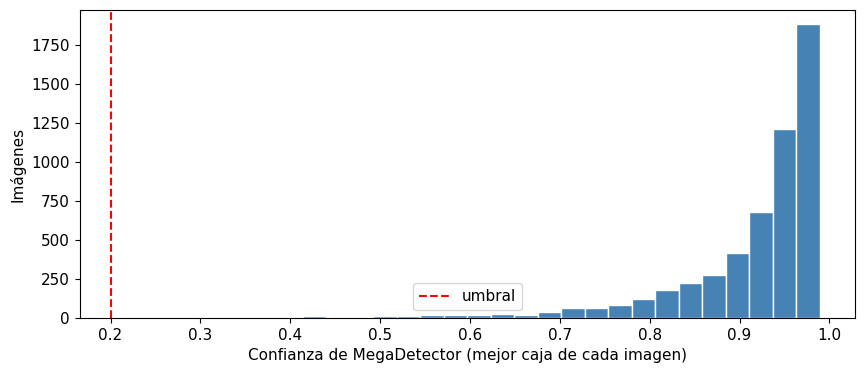

In [15]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(single_animal_bboxes["detectionConfidence"].dropna(), bins=30, color="steelblue", edgecolor="white")
ax.axvline(DETECTION_CONFIDENCE_THRESHOLD, color="red", linestyle="--", label="umbral")
ax.set_xlabel("Confianza de MegaDetector (mejor caja de cada imagen)")
ax.set_ylabel("Imágenes")
ax.legend()
plt.show()

In [16]:
def plot_images_with_boxes(images, animal_boxes, title, n_columns=4, max_images=12):
    images = images.head(max_images)
    if images.empty:
        print(f"{title}: no hay imágenes que mostrar")
        return

    n_rows = int(np.ceil(len(images) / n_columns))
    fig, axes = plt.subplots(n_rows, n_columns, figsize=(4.5 * n_columns, 3.4 * n_rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")

    for ax, image_row in zip(axes.flat, images.itertuples()):
        with Image.open(DATASET_DIR / image_row.filePath) as image:
            image.thumbnail((800, 800))
            ax.imshow(image)
            image_width, image_height = image.size

        image_boxes = animal_boxes[animal_boxes["filePath"] == image_row.filePath]
        for box in image_boxes.itertuples():
            ax.add_patch(
                patches.Rectangle(
                    (box.bboxX * image_width, box.bboxY * image_height),
                    box.bboxWidth * image_width,
                    box.bboxHeight * image_height,
                    fill=False,
                    edgecolor="lime",
                    linewidth=2,
                )
            )
            ax.text(box.bboxX * image_width, box.bboxY * image_height, f"{box.detectionConfidence:.2f}",
                    color="black", backgroundcolor="lime", fontsize=8)
        ax.set_title(f"{image_row.commonName}\n{image_row.lighting} | {len(image_boxes)} caja(s)", fontsize=9)

    fig.suptitle(title, fontsize=13, y=1.02)
    plt.tight_layout()
    plt.show()

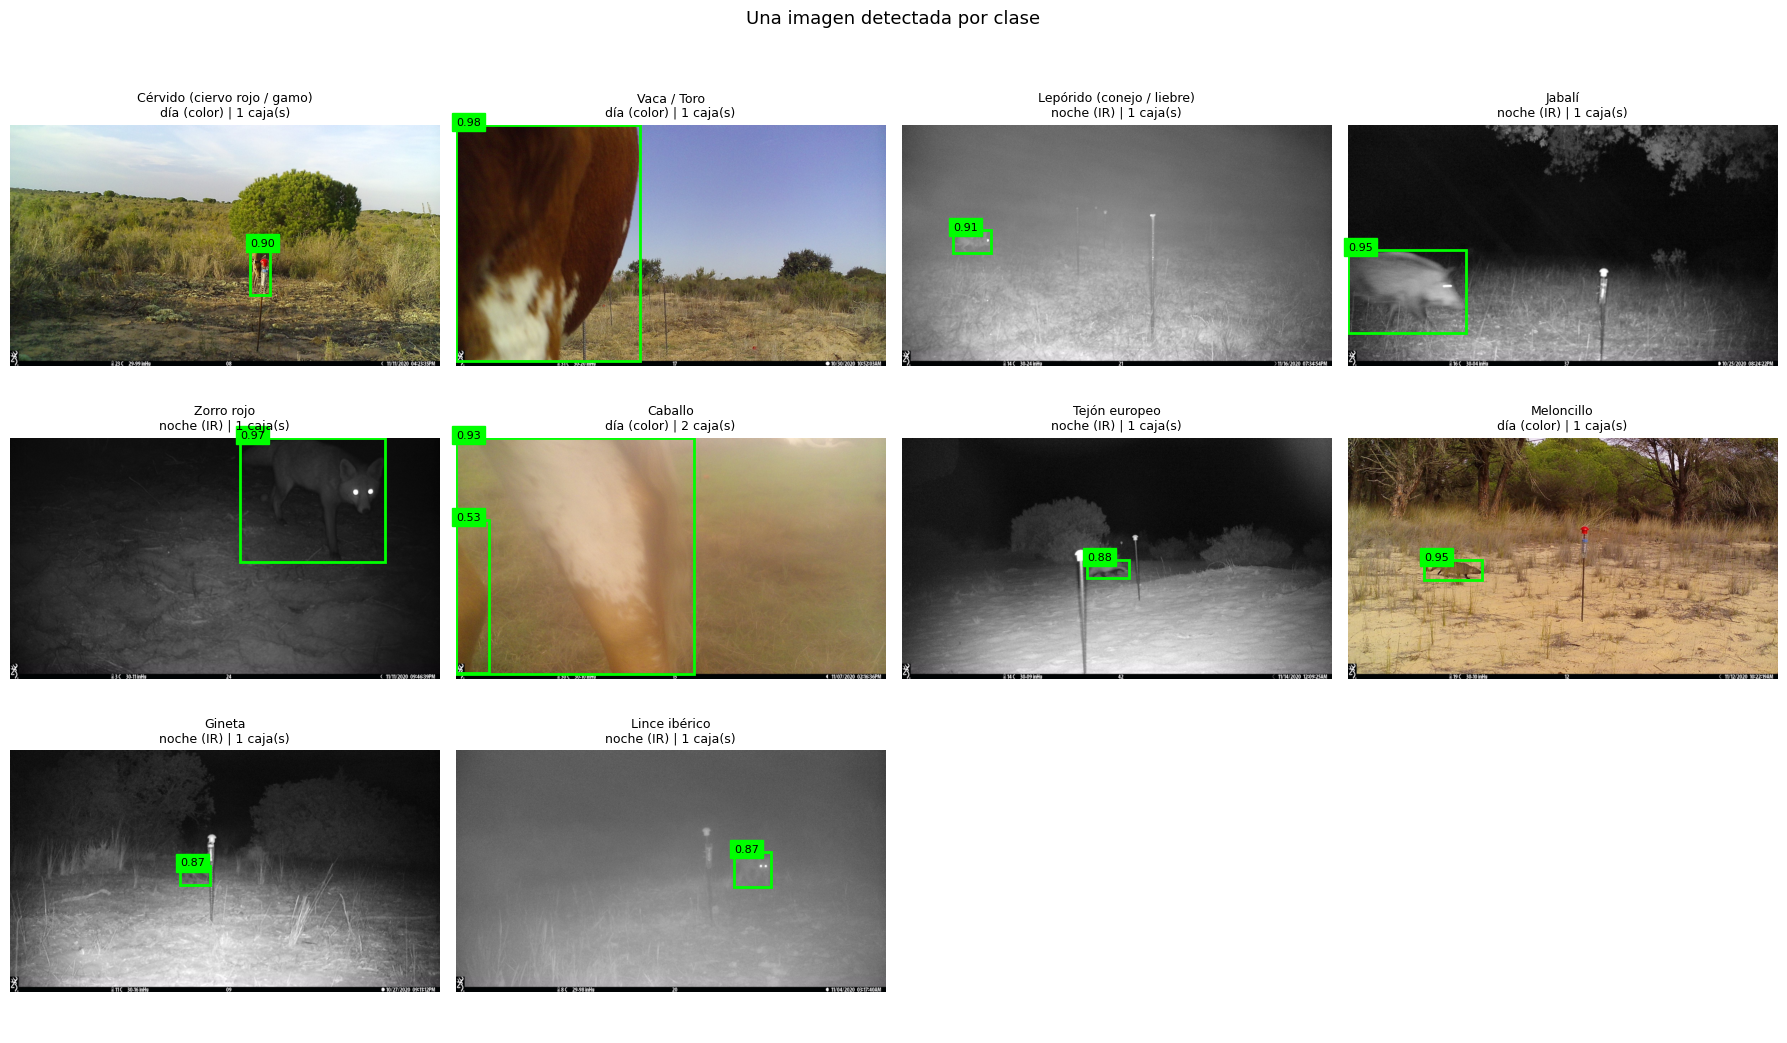

In [17]:
one_detected_image_per_class = (
    single_animal_bboxes[single_animal_bboxes["detectionStatus"] == "detected"]
    .sample(frac=1, random_state=RANDOM_SEED)
    .drop_duplicates("className")
)
plot_images_with_boxes(one_detected_image_per_class, animal_boxes, "Una imagen detectada por clase", max_images=16)

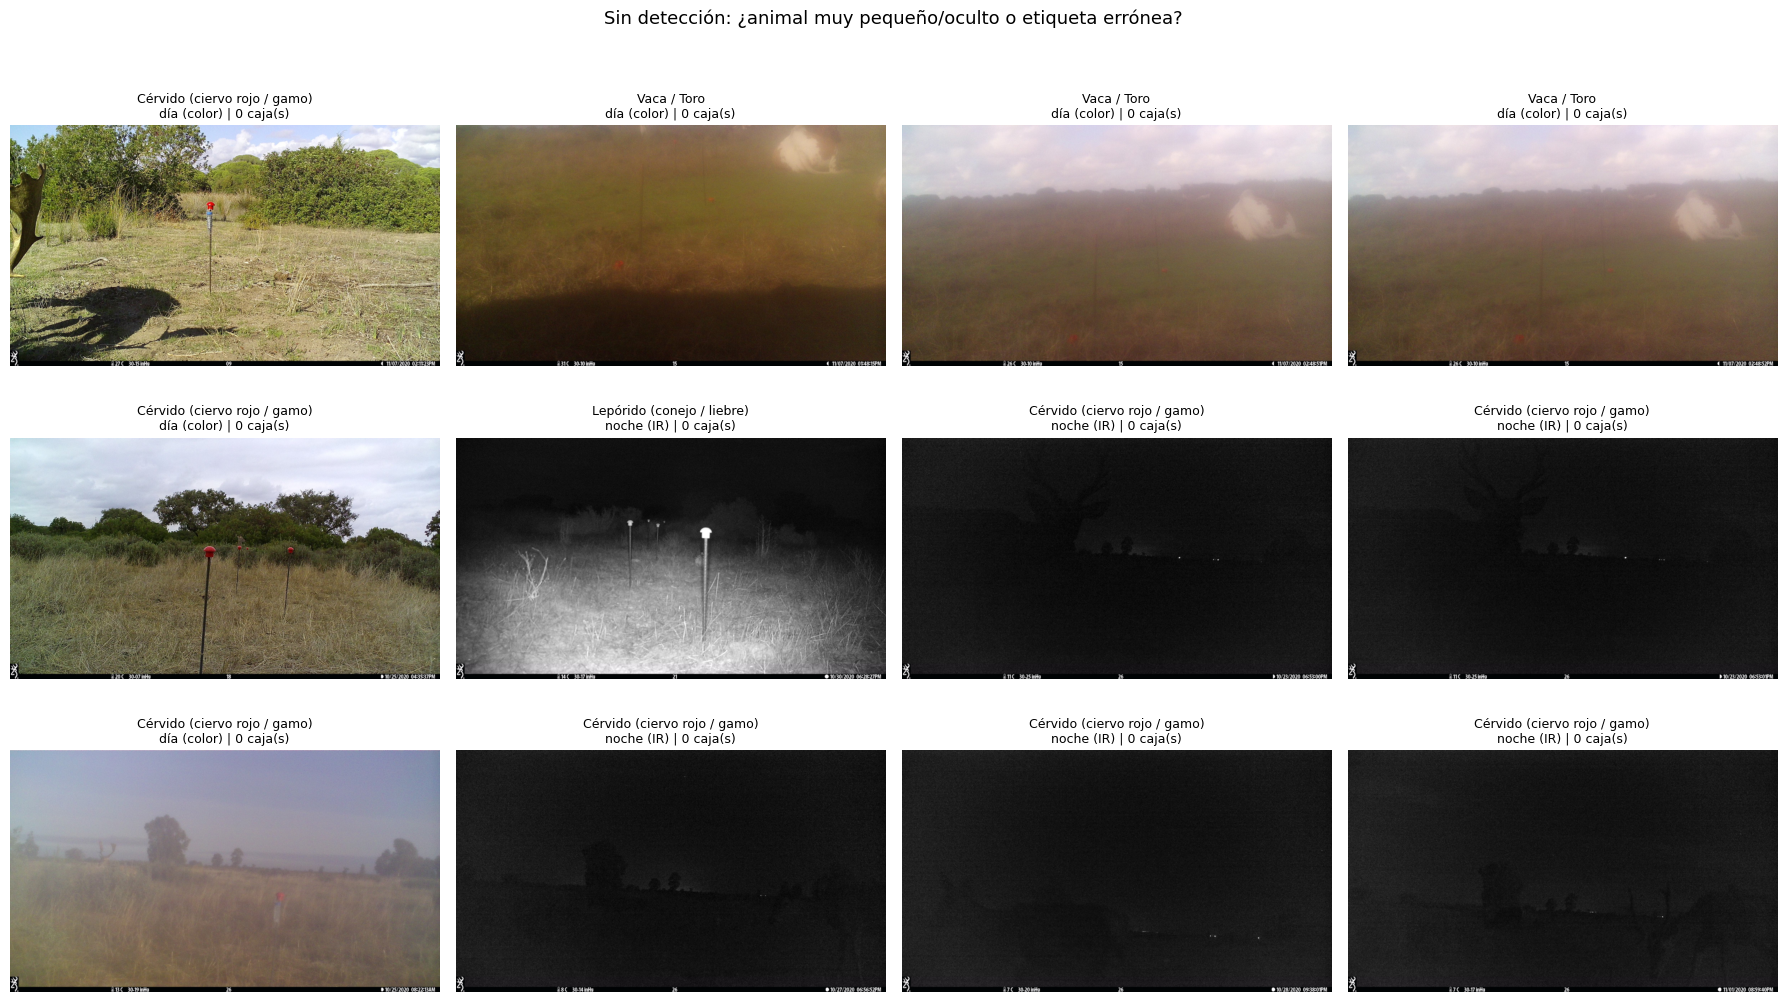

In [18]:
plot_images_with_boxes(
    single_animal_bboxes[single_animal_bboxes["detectionStatus"] == "no_detection"],
    animal_boxes,
    "Sin detección: ¿animal muy pequeño/oculto o etiqueta errónea?",
)

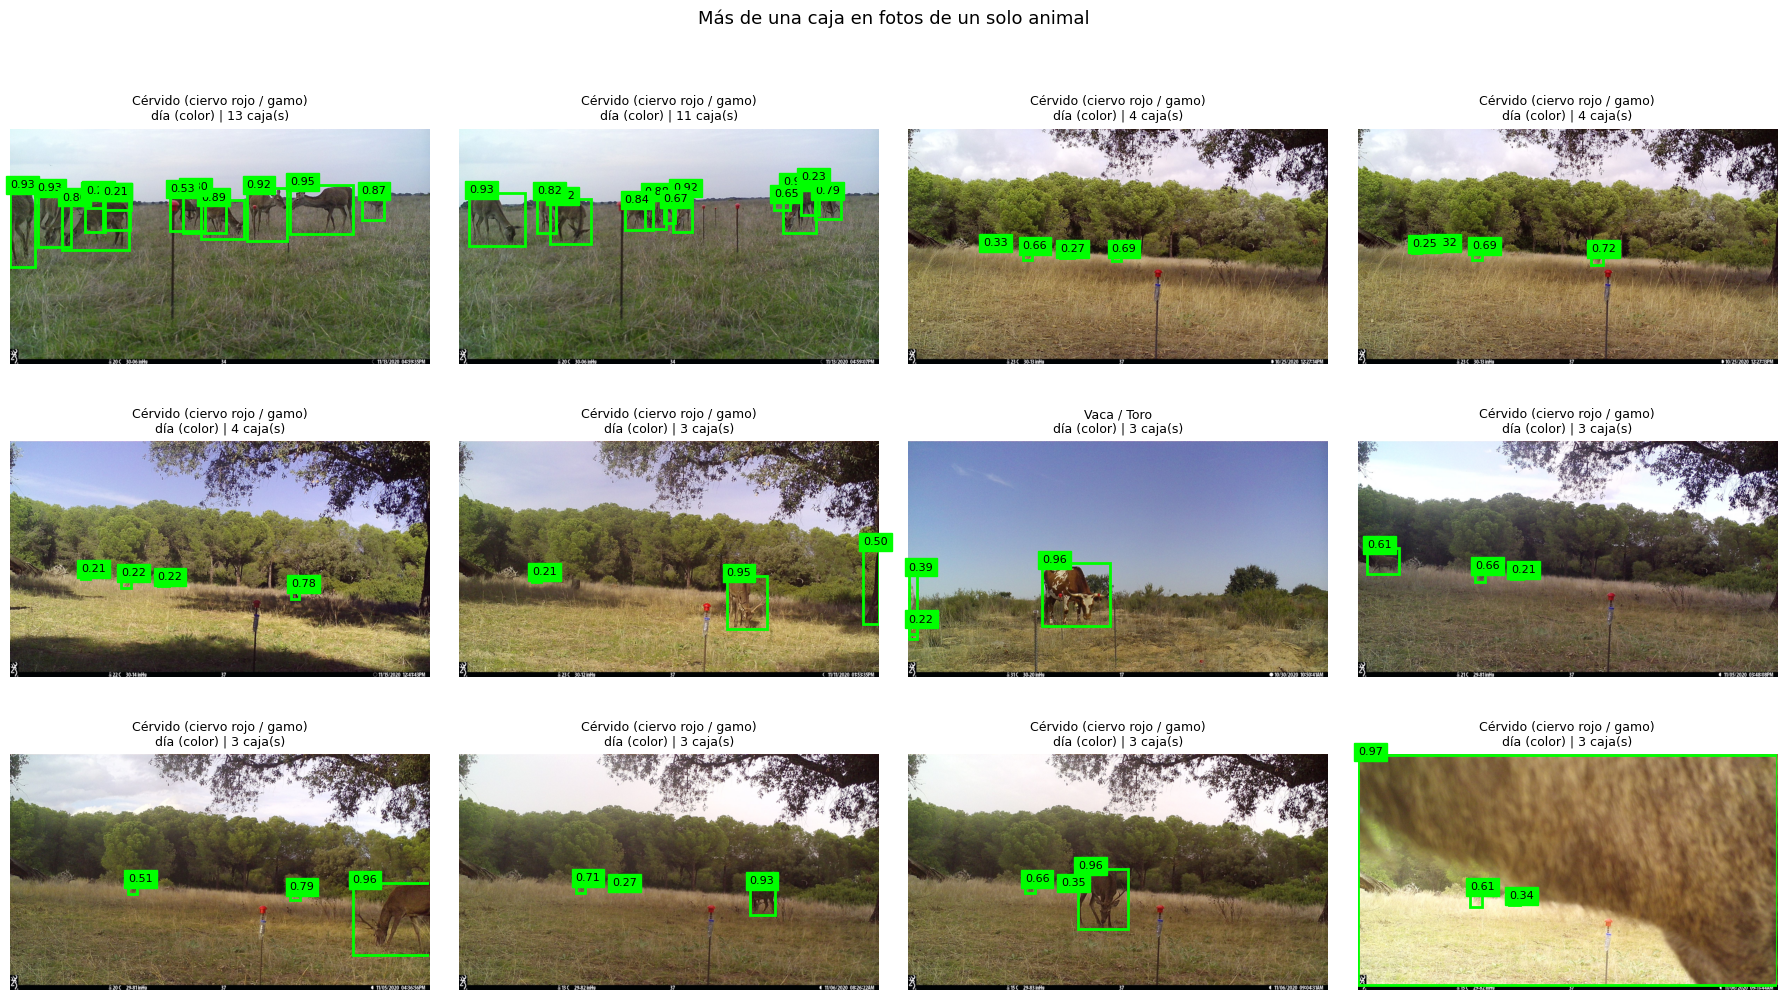

In [19]:
plot_images_with_boxes(
    single_animal_bboxes[single_animal_bboxes["extraAnimalBoxes"] > 0].sort_values("extraAnimalBoxes", ascending=False),
    animal_boxes,
    "Más de una caja en fotos de un solo animal",
)

## 7. Salidas

| Fichero | Contenido |
|---|---|
| `single_animal_images.csv` | Imágenes limpias con un único animal: `className` (familias fusionadas) y `specificSpecies` |
| `megadetector_<scope>.json` | Salida cruda de MegaDetector (rutas relativas a `dona_24/`) |
| `megadetector_animal_boxes.csv` | Todas las cajas de animal por encima del umbral, una fila por caja |
| `single_animal_bboxes.csv` | Una fila por imagen de un animal: `className`, `specificSpecies`, caja (`bboxX…bboxHeight`), confianza, `extraAnimalBoxes`, `detectionStatus`, `lighting` |